INSTALL THE NEEDED LIBRARIES

In [34]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sb


LOAD DATA

In [35]:
df = pd.read_csv('/Users/taahaar/Documents/GitHub/Employee-Attrition-Predictor/.kaggle-datasets/pavansubhasht__ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv')
df.head()   # gets the first 5 rows of the dataset

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


EXPLORATORY DATA ANALYSIS (EDA) - checking the shapes, distributions, column types , and missing values

In [36]:
df.shape    # gets the number of rows and columns in the dataset

(1470, 35)

In [37]:
df.dtypes   #gets the column names and their data types 

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [38]:
df.isnull().sum() # checks for missing values in the dataset

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [39]:
df['Attrition'].value_counts() # checks the number of employees who left and those who stayed

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [40]:
df['StandardHours'].value_counts()

StandardHours
80    1470
Name: count, dtype: int64

In [41]:
df['EmployeeCount'].value_counts()

EmployeeCount
1    1470
Name: count, dtype: int64

In [42]:
df['Over18'].value_counts()

Over18
Y    1470
Name: count, dtype: int64

In [43]:
#columns_list= df.columns.tolist()  # gets the column names in the dataset
for column in df.columns:
    if df[column].nunique() == 1:  # checks for columns with only one unique value
        print(f'Column Name: {column}\n')
        print(df[column].value_counts())

Column Name: EmployeeCount

EmployeeCount
1    1470
Name: count, dtype: int64
Column Name: Over18

Over18
Y    1470
Name: count, dtype: int64
Column Name: StandardHours

StandardHours
80    1470
Name: count, dtype: int64


From this we can understand that the columns: EmployeeCount, Over18, Standard Hours all hold the same values for all the rows so meaning they are useless columns that give us no information. We can go ahead and drop these columns and clean the dataset a bit more

CLEAN THE DATASET/ DROP THE UNECESSARY COLUMNS

In [44]:
# drop columns with only one unique value
df.drop(['StandardHours', 'EmployeeCount', 'Over18'], axis=1, inplace=True)

DATA ANALYSIS by 'Attrition'

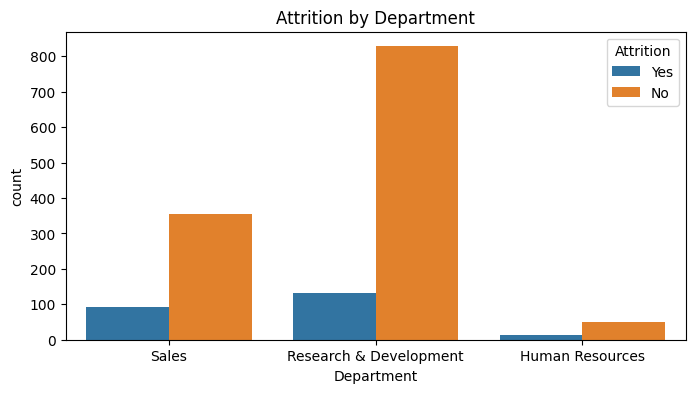

In [45]:
# Evaluating/ analyzing the dataset to find patterns
# Attrtion by Department
plt.figure(figsize=(8,4))
sb.countplot(x='Department', hue='Attrition', data=df)
plt.title('Attrition by Department')
plt.show()

For attrition by Department, Sales has the highest attrition rate relative to its size. The Research and Development Department has the most employees overall but also has the most mployees leaving. Human Resources department doesn't have that many employees and also doesn't have that many employees leaving. Though, Sales has the highest attrition rate meaning employees are more likely to leave that department

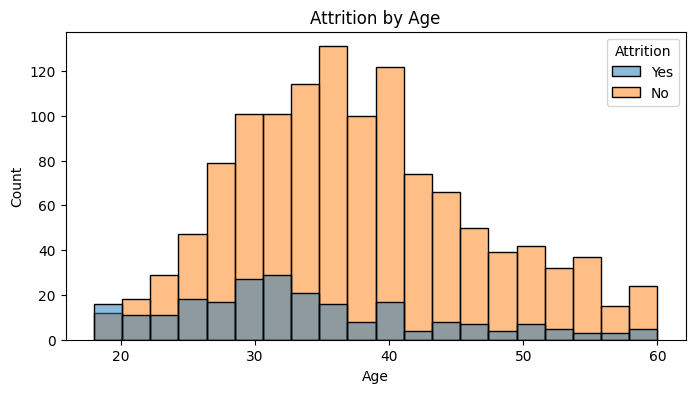

In [46]:
# Attrition by Age
plt.figure(figsize=(8,4))
sb.histplot(data=df, x='Age', hue='Attrition', bins=20)
plt.title('Attrition by Age')
plt.show()

For attrition by Age, younger people in their 20s - 30s are more likely to leave as compared to the older people over the age of 40. This would make sense younger people are still figuring out their life and career whereas the older people stick to their jobs.

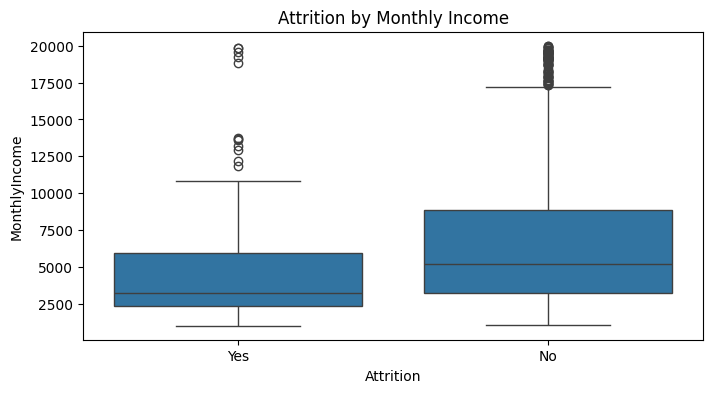

In [47]:
#Attrition by Monthly Income
plt.figure(figsize=(8,4))
sb.boxplot(x='Attrition', y='MonthlyIncome', data=df)
plt.title('Attrition by Monthly Income')
plt.show()

For attrition by Monthly Income, from the boxplot we see the median leans much more towards the bottom of the box (left-heavy). This indicates that lower income paid employees are most likely to leave than the employees that make more money, which makes total sense. 

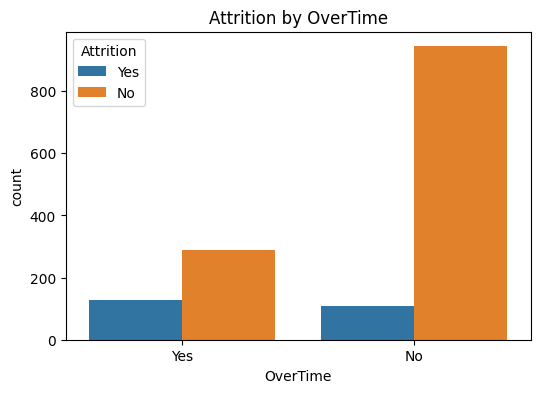

In [48]:
# Attrition by OverTime
plt.figure(figsize=(6,4))
sb.countplot(x='OverTime', hue='Attrition', data=df)
plt.title('Attrition by OverTime')
plt.show()

For Atrrition by OverTime, it is noticeably visible that the employees that do work overtime are the ones that are most likey to leave than compared to the employees who don't work overtime. 

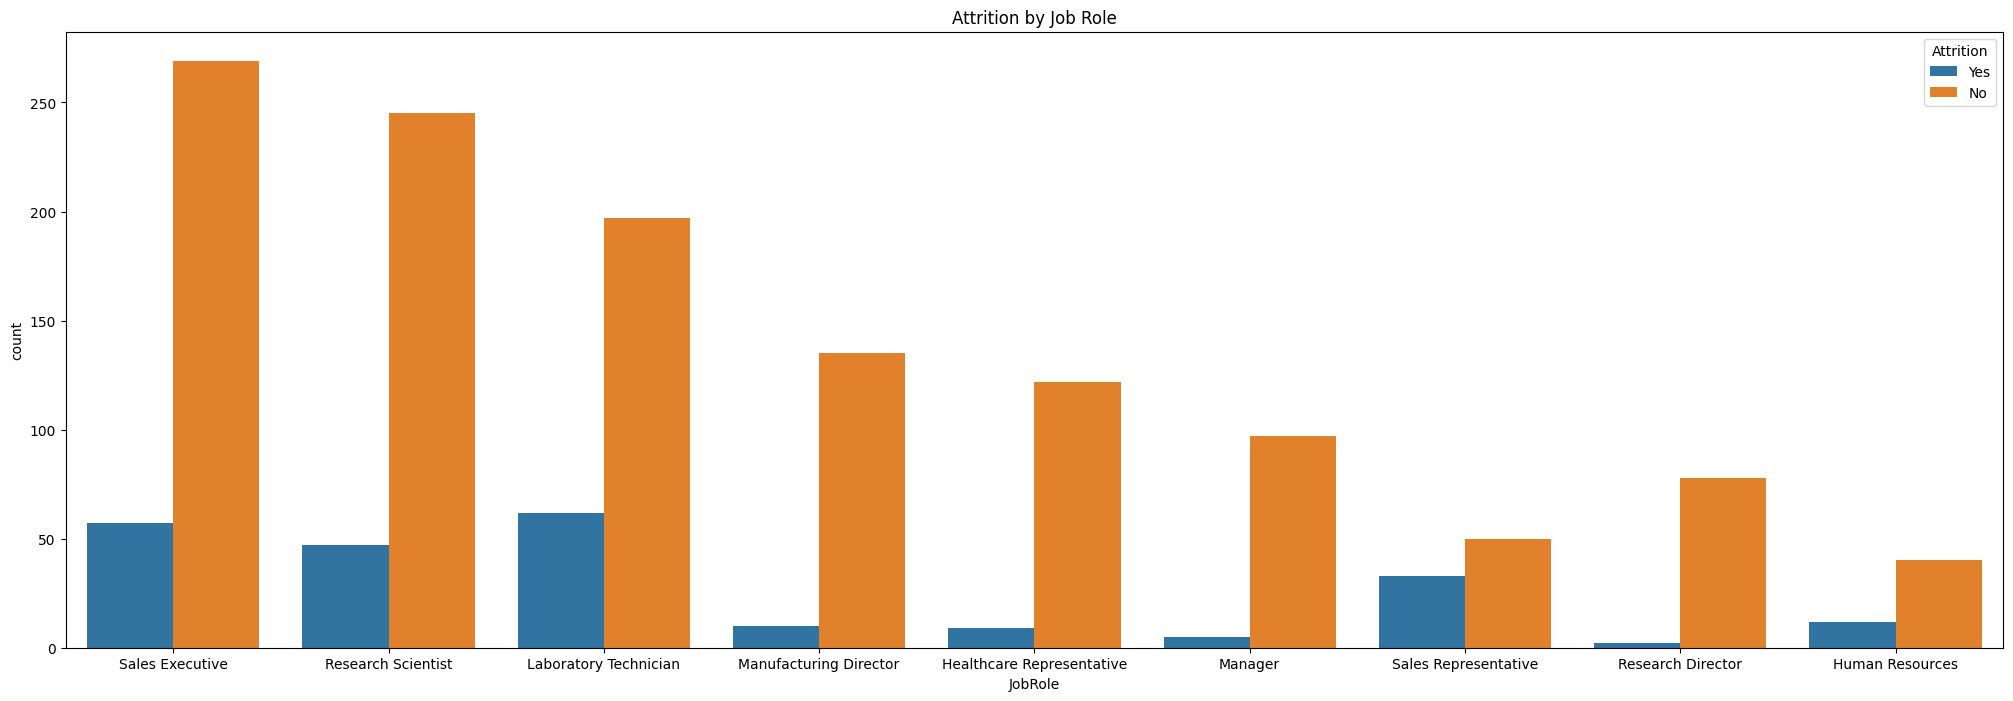

In [49]:
# Attrition by Job Role
plt.figure(figsize=(25,8))
sb.countplot(x='JobRole', hue='Attrition', data=df)
plt.title('Attrition by Job Role')
plt.show()

For attrition by Job Role, the roles with the highest attrition rates are: Sales Representative, Labratory technician, Reaseach scientist and maybe Human Resources. For Sales roles it makes sense as from out first attrition plot above, Sales department had the highest attrition rate. For Roles like Manager and director, the attrition rate is very low meaning the employees stayed which makes sense because higher pay. 

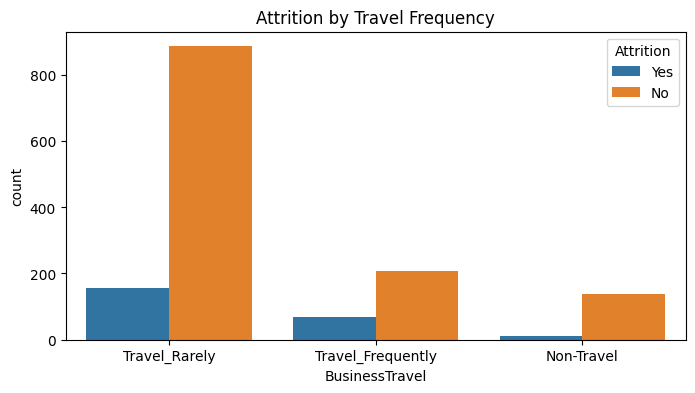

In [50]:
# attrition by Travel Frequency
plt.figure(figsize=(8,4))
sb.countplot(x='BusinessTravel', hue='Attrition', data=df)
plt.title('Attrition by Travel Frequency')
plt.show()

For Attrition by Business Travel, employees who travel frequently has a higher attrition rate to those who either have a non-travel role or they travel rarely

DATA PREPARATION (BUILDING THE MODEL)

When building the model, we have to encode the categorical variables by turning into numbers ---> models only work with models

In [51]:

# Drop Employee Number as it is useless information for the model to train on
df = df.drop(columns=['EmployeeNumber'], errors='ignore')

# Label Encoding the categorical variable
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})

# Turn the rest of the categorical variables to 0/1 columns
column = df.select_dtypes(exclude='number').columns     #exclude columns that already have numeric values
df = pd.get_dummies(df, columns = column, drop_first=True, dtype = 'int')

df.shape

df.head


<bound method NDFrame.head of       Age  Attrition  DailyRate  DistanceFromHome  Education  \
0      41          1       1102                 1          2   
1      49          0        279                 8          1   
2      37          1       1373                 2          2   
3      33          0       1392                 3          4   
4      27          0        591                 2          1   
...   ...        ...        ...               ...        ...   
1465   36          0        884                23          2   
1466   39          0        613                 6          1   
1467   27          0        155                 4          3   
1468   49          0       1023                 2          3   
1469   34          0        628                 8          3   

      EnvironmentSatisfaction  HourlyRate  JobInvolvement  JobLevel  \
0                           2          94               3         2   
1                           3          61               2  

In [52]:
# Split into Train and Test
from sklearn.model_selection import train_test_split

X = df.drop('Attrition', axis=1)
y = df['Attrition']

# split using the imported function
X_train, X_test, y_train, y_test = train_test_split(X, y,random_state=42, test_size=0.2,  stratify=y )

X.head()

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1102,1,2,2,94,3,2,4,5993,...,0,0,0,0,0,1,0,0,1,1
1,49,279,8,1,3,61,2,2,2,5130,...,0,0,0,0,1,0,0,1,0,0
2,37,1373,2,2,4,92,2,1,3,2090,...,1,0,0,0,0,0,0,0,1,1
3,33,1392,3,4,4,56,3,1,3,2909,...,0,0,0,0,1,0,0,1,0,1
4,27,591,2,1,1,40,3,1,2,3468,...,1,0,0,0,0,0,0,1,0,0


TRAIN THE MODELS

In [53]:
# initialize the model
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Put aall numbers on the same scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

# TRAIN the model
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# Evaluate
accuracy = model.score(X_test_scaled, y_test)
print(f"Model Accuracy: {accuracy}")

#classification report
report = classification_report(y_test, model.predict(X_test_scaled))
print(report)

Model Accuracy: 0.7517006802721088
              precision    recall  f1-score   support

           0       0.92      0.77      0.84       247
           1       0.35      0.66      0.46        47

    accuracy                           0.75       294
   macro avg       0.64      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf_model = RandomForestClassifier(n_estimators=200, random_state = 42, class_weight='balanced')
rf_model.fit(X_train, y_train)

print(f"random Forest accuracy: {rf_model.score(X_test, y_test)}")
print(classification_report(y_test, rf_model.predict(X_test)))

random Forest accuracy: 0.826530612244898
              precision    recall  f1-score   support

           0       0.87      0.93      0.90       247
           1       0.44      0.30      0.35        47

    accuracy                           0.83       294
   macro avg       0.66      0.61      0.63       294
weighted avg       0.80      0.83      0.81       294



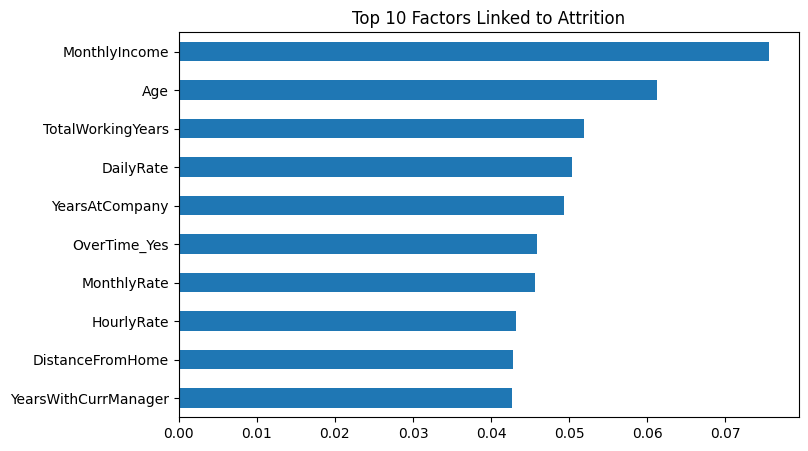

In [55]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances.sort_values().tail(10).plot(kind='barh', figsize=(8,5), title='Top 10 Factors Linked to Attrition')
plt.show()

In [58]:
import joblib
joblib.dump(model, 'model/attrition_model.joblib')
joblib.dump(scaler, 'model/scaler.joblib')

['model/scaler.joblib']

In [ ]:
# Check to see if the model was saved properly
loaded_model = joblib.load('model/attrition_model.joblib')
print(loaded_model.score(X_test_scaled, y_test))

0.7517006802721088
